In [1]:
########################################################
###################### Importierte Packete #############
########################################################

import matplotlib
import matplotlib.pyplot as plt
from matplotlib import rc                                                   # To use a LaTeX font
from matplotlib import cm
from matplotlib.colors import ListedColormap, LinearSegmentedColormap
from matplotlib.colors import rgb2hex

#import csv

import numpy as np

import pandas as pd

import scipy
from scipy import stats
import scipy.constants as sc
from scipy import ndimage
import scipy.signal
from scipy.interpolate import interp1d

import statsmodels.api as sm

from mpl_toolkits import mplot3d                                            # Um 3D Plots zu machen

import os

##### Saving/packing of data
import pickle

##### To create colour gradients
from colour import Color

In [2]:
# importing the own functions from the scientific_utils package
from scientific_utils.general.plotting import Convert_cm_To_inch
from scientific_utils.impedance.plotting import Matplotlib_XvsY_And_Data_Extraction

In [3]:
# create the output folder if it does not exist yet
if not os.path.exists('./images/'):
    os.mkdir('./images/')

In [4]:
#########################################################
##################### Start of the code ##################
#########################################################

In [5]:
########## Open the .pkl file ########

##### OCVs after a Charging step in the C Rate Test
#with open('./data/processed/list_of_dataframes_of_OCV_charge.pkl', 'rb') as f:
#    list_of_dataframes_of_OCV_charge = pickle.load(f)

##### OCVs after a Discharging step in the C Rate Test
#with open('./data/processed/list_of_dataframes_of_OCV_discharge.pkl', 'rb') as f:
#    list_of_dataframes_of_OCV_discharge = pickle.load(f)    

##### Impedance spectra after a Charging step in the C Rate Test
with open('./data/processed/list_of_dataframes_of_PEIS_charge.pkl', 'rb') as f:
    list_of_dataframes_of_PEIS_charge = pickle.load(f)      
    
##### Impedance spectra after a Discharging step in the C Rate Test
with open('./data/processed/list_of_dataframes_of_PEIS_discharge.pkl', 'rb') as f:
    list_of_dataframes_of_PEIS_discharge = pickle.load(f)    

#print(list_of_dataframes_of_PEIS_discharge)

########## Create a list with more information about the data for plotting later #######
list_RateTest_labels = [0.10, 0.33, 1.00, 5, 5]


In [6]:
########## Define colours by hex code ##########
yellow = '#ffa200'
orange = '#f97625'
lightpink = '#e94a3a'
pink = '#ce1b49'
lightpurple = '#a90054'
purple = '#7e0059'
darkpurple = '#4c0057'
darkblue = '#0a004d'

########## Colours in a list to access them in a for loop ##########
colors = [yellow, orange, lightpink, pink, lightpurple, purple, darkpurple, darkblue]


########## Colour gradient with the colour package
#beginnig_color = Color("yellow")
#end_color = Color("blue")
#number_of_colorpoints = 4
#color_gradient = list(beginnig_color.range_to(end_color,number_of_colorpoints))
#print(color_gradient)


########## Cologradient with Matplotlib Colormaps
# Available colormaps: https://matplotlib.org/3.1.0/tutorials/colors/colormaps.html#ibm
number_of_colorpoints = 3 # number of colour points taken from the colour gradient with equal distance
colormap = plt.get_cmap('coolwarm', number_of_colorpoints) # Loads a ready-made colormap from Matplotlib
array_of_RGBAcolors = colormap(range(number_of_colorpoints)) # Returns the colormap as RGBA values scaled from 0 to 1
list_of_Hexcolors = [ rgb2hex(array_of_RGBAcolors[i,:]) for i in range(array_of_RGBAcolors.shape[0]) ] # Converts the scaled RGBA values to hex code and puts them in a list


In [7]:
########## Font settings for the PGF file ##########
pgf_with_latex = {                      # setup matplotlib to use latex for output
    #"pgf.texsystem": "xelatex",         # change this if using xetex or lautex
    "text.usetex": False,                # use LaTeX to write all text
    "pgf.rcfonts": True,               # don't setup fonts from rc parameters
    "font.family": "sans-serif",           # standard sans-serif font of Matplotlib
    #"mathtext.fontset": "stixsans",
    "legend.title_fontsize" : 14,
    "legend.fontsize": 10,              # Make the legend/label fonts a little smaller
    "axes.labelsize": 12,               # LaTeX default is 10pt font.
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "figure.figsize" : Convert_cm_To_inch(16, 8),
    'savefig.dpi'         : 300,   ## figure dots per inch or 'figure'
    'savefig.facecolor'   : 'white',    ## figure facecolor when saving
    'savefig.edgecolor'   : 'white',    ## figure edgecolor when saving
    'savefig.format'      : 'png',      ## png, ps, pdf, svg
    'savefig.bbox'        : 'tight', 
    "pgf.preamble": "\n".join([
        r"\usepackage[T1]{fontenc}",    # use utf8 fonts becasue your computer can handle it :)
        r"\usepackage{fontspec}",        # plots will be generated using this preamble
        r"\usepackage{fourier}",
        r"\usepackage{unicode-math}",
        r"\usepackage[basic,italic,symbolgreek,numbers]{mathastext}"
        ])
    }

plt.rcParams.update(pgf_with_latex)

##### one style for all plots: the shared publication style (scientific_utils.general.plotting) replaces the local settings above
from scientific_utils.general.plotting import pgf_with_latex
plt.rcParams.update(pgf_with_latex)

In [8]:
###################################### Definition of Functions ###############################

In [9]:
list_of_dataframes_of_PEIS_charge_cleaned = list_of_dataframes_of_PEIS_charge
#print(list_of_dataframes_of_PEIS_charge_cleaned[0])

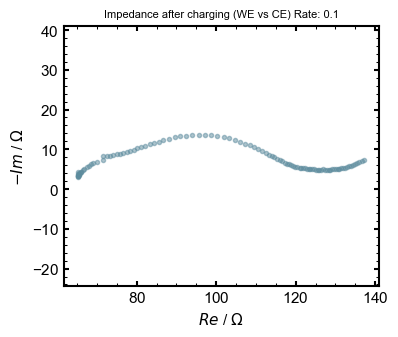

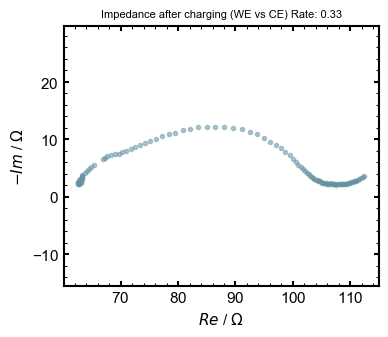

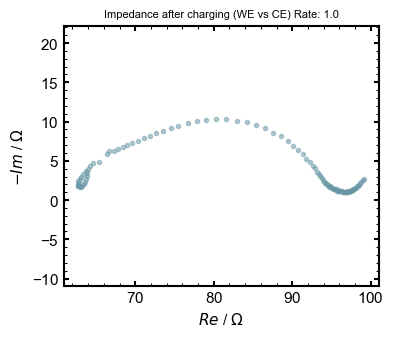

In [10]:
list_of_dataframes = list_of_dataframes_of_PEIS_charge_cleaned
x_values_column_name = 'Re(Zwe-ce)/Ohm'
y_values_column_name = '-Im(Zwe-ce)/Ohm'
y_ax_label = r'$-Im $ / $\Omega $ '
x_ax_label = r'$Re $ / $\Omega $ '
rate_to_save = -1
additional_name = 'charge'
legend_title = 'Impedance after charging (WE vs CE)'

Matplotlib_XvsY_And_Data_Extraction(list_of_dataframes, x_values_column_name, y_values_column_name, y_ax_label, x_ax_label, rate_to_save, additional_name, legend_title, list_RateTest_labels)

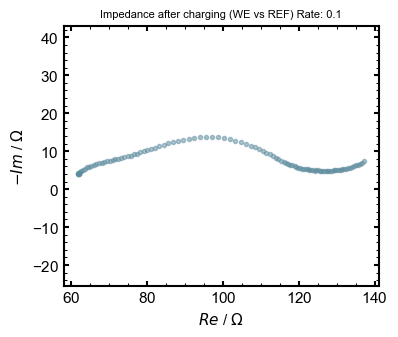

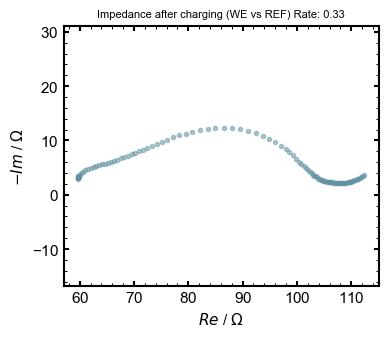

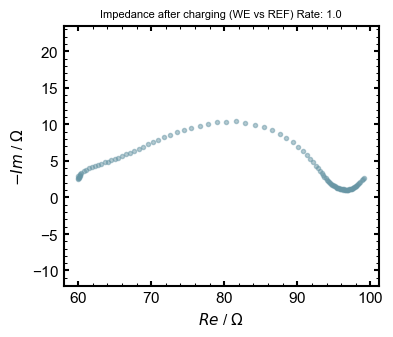

In [11]:
list_of_dataframes = list_of_dataframes_of_PEIS_charge_cleaned
x_values_column_name = 'Re(Z)/Ohm'
y_values_column_name = '-Im(Z)/Ohm'
y_ax_label = r'$-Im $ / $\Omega $ '
x_ax_label = r'$Re $ / $\Omega $ '
rate_to_save = -1
additional_name = 'charge'
legend_title = 'Impedance after charging (WE vs REF)'

Matplotlib_XvsY_And_Data_Extraction(list_of_dataframes, x_values_column_name, y_values_column_name, y_ax_label, x_ax_label, rate_to_save, additional_name, legend_title, list_RateTest_labels)

In [12]:
# Deleting unneccesary Data of CP charge
#list_of_dataframes = list_of_dataframes_of_PEIS_discharge

#list_of_dataframes_of_PEIS_discharge_cleaned = DeleteListEntries(list_of_dataframes)
list_of_dataframes_of_PEIS_discharge_cleaned = list_of_dataframes_of_PEIS_discharge
#print(list_of_dataframes_of_CP_charge_equidistant_cleaned)

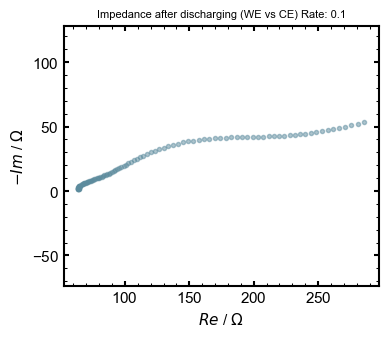

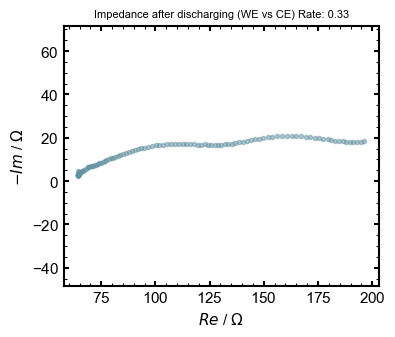

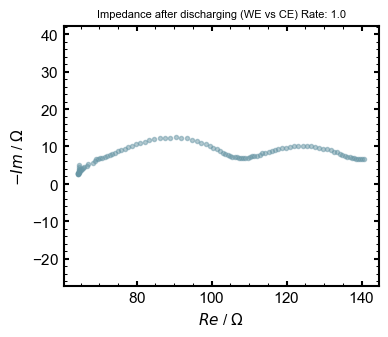

In [13]:
list_of_dataframes = list_of_dataframes_of_PEIS_discharge_cleaned
x_values_column_name = 'Re(Zwe-ce)/Ohm'
y_values_column_name = '-Im(Zwe-ce)/Ohm'
y_ax_label = r'$-Im $ / $\Omega $ '
x_ax_label = r'$Re $ / $\Omega $ '
rate_to_save = -1
additional_name = 'discharge'
legend_title = 'Impedance after discharging (WE vs CE)'

Matplotlib_XvsY_And_Data_Extraction(list_of_dataframes, x_values_column_name, y_values_column_name, y_ax_label, x_ax_label, rate_to_save, additional_name, legend_title, list_RateTest_labels)

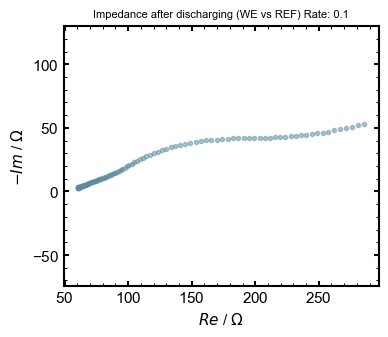

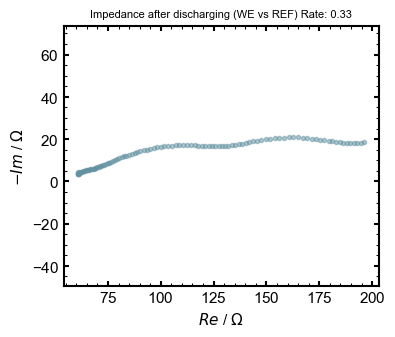

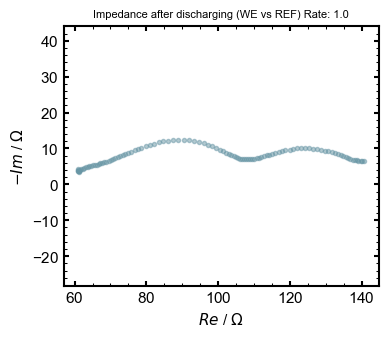

In [14]:
list_of_dataframes = list_of_dataframes_of_PEIS_discharge_cleaned
x_values_column_name = 'Re(Z)/Ohm'
y_values_column_name = '-Im(Z)/Ohm'
y_ax_label = r'$-Im $ / $\Omega $ '
x_ax_label = r'$Re $ / $\Omega $ '
rate_to_save = -1
additional_name = 'discharge'
legend_title = 'Impedance after discharging (WE vs REF)'

Matplotlib_XvsY_And_Data_Extraction(list_of_dataframes, x_values_column_name, y_values_column_name, y_ax_label, x_ax_label, rate_to_save, additional_name, legend_title, list_RateTest_labels)